***LAB 06***

**SUPPORT VECTOR MACHINE (SVM) CLASSIFIER**

Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
data = load_breast_cancer(as_frame=True).frame
print(data.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

Load dataset from CSV (alternative). Works for any csv e.g. Parkinson's disease dataset, just change the file name and the target column name.

In [3]:
#save the dataset to csv
data.to_csv('breast_cancer.csv', index=False)

#load the dataset from csv
data = pd.read_csv('breast_cancer.csv')
print(data.shape)

#for Parkinson's dataset it would be something like:
#data = pd.read_csv('parkinsons.csv')
#data = data.drop(columns='name')   # remove non-numeric id column
#target column is 'status' there, so use y = data['status']

(569, 31)


Data preprocessing

In [4]:
#missing values
print(data.isnull().sum().sum())
data = data.fillna(data.median(numeric_only=True))

#encode categorical columns (none in this dataset)
cat_cols = data.select_dtypes(include='object').columns
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

0


In [5]:
X = data.drop(columns='target')
y = data['target']

#train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#SVM is distance based so scaling is necessary
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Apply Grid Search to find the optimal parameters

In [6]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

grid = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print('Best parameters =', grid.best_params_)
print('Best CV accuracy =', grid.best_score_)

Best parameters = {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy = 0.9802197802197803


Use the best parameters to make predictions on the test set

In [7]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

Evaluate performance

In [8]:
print('Accuracy  =', accuracy_score(y_test, y_pred))
print('Precision =', precision_score(y_test, y_pred))
print('Recall    =', recall_score(y_test, y_pred))
print('F1-score  =', f1_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=['Malignant','Benign']))

Accuracy  = 0.9824561403508771
Precision = 0.9861111111111112
Recall    = 0.9861111111111112
F1-score  = 0.9861111111111112

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Visualize the Confusion Matrix

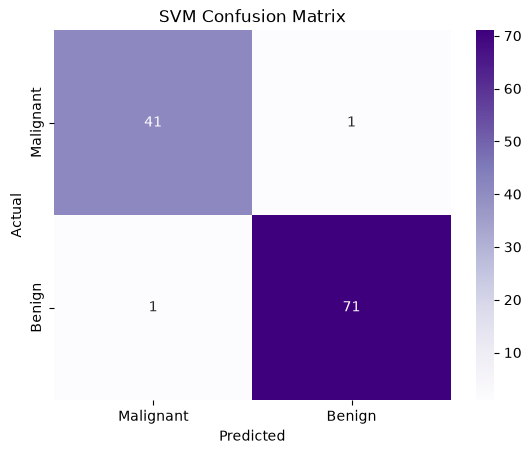

In [9]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=['Malignant','Benign'], yticklabels=['Malignant','Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

Effect of different kernels (using the best C and gamma)

In [10]:
best = grid.best_params_
res = []
for k in ['linear', 'rbf', 'poly', 'sigmoid']:
    m = SVC(kernel=k, C=best['C'], gamma=best['gamma']).fit(X_train, y_train)
    res.append([k, m.score(X_test, y_test)])
print(pd.DataFrame(res, columns=['Kernel', 'Test accuracy']).round(3))

    Kernel  Test accuracy
0   linear          0.982
1      rbf          0.947
2     poly          0.851
3  sigmoid          0.947


Grid search tried every combination of C, kernel and gamma with 5-fold cross validation and picked the one with the best accuracy, so the parameters are chosen without looking at the test data.

A large C gives a hard margin (less misclassification on train data but may overfit), a small C gives a soft margin (wider margin, more tolerant to errors). The kernel table shows that the linear and rbf kernels work best here, which means the data is almost linearly separable.